In [35]:
#Import frameworks
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Load and Inspect dataset

In [4]:
#Load dataset
df = pd.read_csv('Titanic.csv')

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [13]:
df[['Age', 'Sex', 'Pclass', 'Fare', 'Embarked']].info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Sex       891 non-null    str    
 2   Pclass    891 non-null    int64  
 3   Fare      891 non-null    float64
 4   Embarked  889 non-null    str    
dtypes: float64(2), int64(1), str(2)
memory usage: 40.0 KB


In [14]:
df[['Age', 'Sex', 'Pclass', 'Fare', 'Embarked']].describe()

,Age,Pclass,Fare
count,714.000000,891.000000,891.000000
mean,29.699118,2.308642,32.204208
std,14.526497,0.836071,49.693429
min,0.420000,1.000000,0.000000
25%,20.125000,2.000000,7.910400
50%,28.000000,3.000000,14.454200
75%,38.000000,3.000000,31.000000
max,80.000000,3.000000,512.329200


In [8]:
df.shape

(891, 12)

In [15]:
df[['Age', 'Sex', 'Pclass', 'Fare', 'Embarked']].dtypes

Age         float64
Sex             str
Pclass        int64
Fare        float64
Embarked        str
dtype: object

In [19]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Data Wrangling

In [21]:
#Fill Age with median
df['Age'] = df['Age'].fillna(df['Age'].median())

#Fill embarked with mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode())
df['Cabin'] = df['Cabin'].fillna(df['Cabin'].mode())

In [22]:
#Encode categorical variables
#Encoding Sex
df['Sex'] = df['Sex'].map({'male':0, 'female':1})
#Encoding Embarked
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

EDA

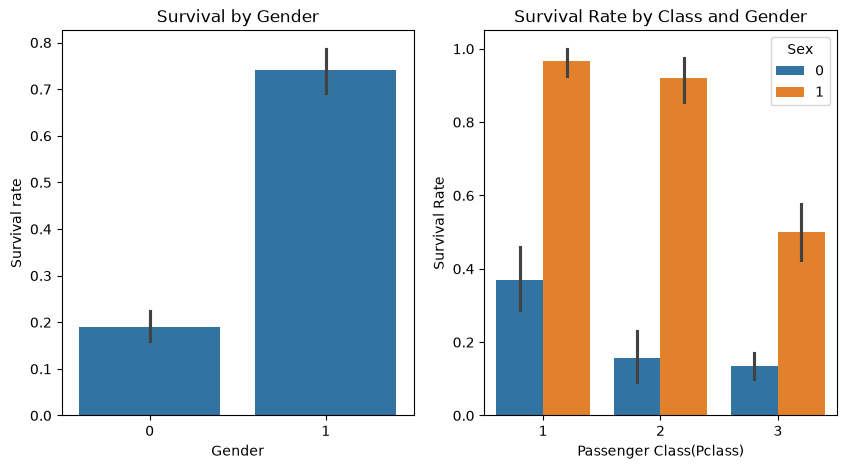

In [27]:
#Plot survival rate by gender and class
plt.figure(figsize=(10,5))

#Survival rate by gender
plt.subplot(1,2,1)
sns.barplot(x='Sex', y='Survived', data=df)
plt.title('Survival by Gender')
plt.xlabel('Gender')
plt.ylabel('Survival rate')

#Survival by Pclass
plt.subplot(1,2,2)
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=df)
plt.title('Survival Rate by Class and Gender')
plt.xlabel('Passenger Class(Pclass)')
plt.ylabel('Survival Rate')
plt.show()

- Gender - Female passengers had a signicant higher survival rate compared to te male passengers.
- Passengers in 1st class had higher survival rates across both genders compared to 2nd and 3rd class passengers.

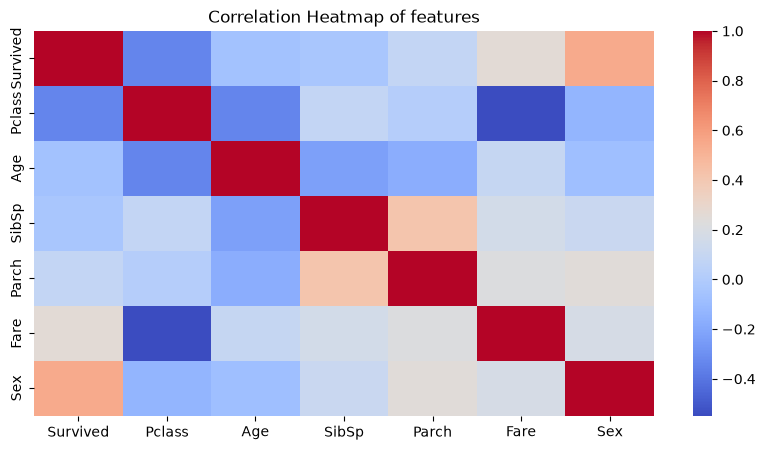

In [30]:
#Correlation heatmap of features
plt.figure(figsize=(10,5))
numeric_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex']
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title('Correlation Heatmap of features')
plt.show()

- Variables 'Sex', 'Pclass' and 'Fare' share a strong linear relationships with 'Survived' makng them essential features for training an accurate predictive classification model.

Model Building

In [34]:
#Define feature variables and target variable
features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex', 'Embarked_Q', 'Embarked_S']
X= df[features]
y= df['Survived']

#train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Initialize and train Logistic Regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

#Initialize and train Random Forest Classifier
rand_forest = RandomForestClassifier(random_state=42)
rand_forest.fit(X_train, y_train)

print('Model training complete')

Model training complete


Prediction and Evaluation

In [36]:
#Predictions
lr_pred = log_reg.predict(X_test)
rf_pred = rand_forest.predict(X_test)

In [40]:
#Evaluations
#Logistic Regression Evaluation
print(f'Accuracy: {accuracy_score(y_test, lr_pred):.4f}\n')
print('Confusion Matrix:')
print(confusion_matrix(y_test, lr_pred))
print('\nClassification Report:')
print(classification_report(y_test, lr_pred))

Accuracy: 0.8101

Confusion Matrix:
[[90 15]
 [19 55]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       105
           1       0.79      0.74      0.76        74

    accuracy                           0.81       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



In [41]:
#Random Forest Evaluation
print(f'Accuracy: {accuracy_score(y_test, rf_pred):.4f}\n')
print('Confusion Matrix')
print(confusion_matrix(y_test, rf_pred))
print('\nClassification Report:')
print(classification_report(y_test, rf_pred))

Accuracy: 0.8212

Confusion Matrix
[[92 13]
 [19 55]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179

